# 03. 오차 분석 & 진단 (2주차)

1주차 베이스라인 **E. LGBM-판매일** (3-fold 평균 SMAPE 0.556)을 출발점으로,
**"모델이 어디서, 왜 틀리는가"** 를 찾는 것이 이번 주 목표입니다. 점수를 올리는 건 3주차에 하고, 이번 주는 **원인을 찾는 주**예요.

### 이번 주에 답할 질문
| # | 질문 | 왜 중요한가 |
|---|------|------------|
| 0 | 점수 차이가 얼마나 나야 "진짜 개선"인가? | 앞으로 모든 실험의 판정 기준 (우연과 진짜를 구분) |
| 1 | 어느 영업장·시기·요일·며칠 뒤 예측에서 많이 틀리나? | 약점의 위치 파악 |
| 2 | **업장이 휴장 중인가, 메뉴만 안 팔리는가**에 따라 오차가 다른가? | 1주차 질문에서 나온 아이디어 → 3주차 피처 근거 |
| 3 | 28일 내내 0이던 메뉴에 모델이 몇 개를 예측하나? | "0 대신 평소 판매량" 보험 전략 점검 |
| 4 | 연회장은 왜 잘 맞고, 어떤 메뉴가 어려운가? | 잘 되는 이유 → 다른 영업장에 응용 |
| 5 | fold1이 나쁜 건 **공부량 부족** 때문인가? | 진단 실험 (학습 기간 줄여보기) |
| 6 | `dayofyear`를 빼면 어떻게 되나? | "날짜 외우기" 의존도 확인 |

> ⏱️ 모델을 20번 정도 학습시키므로 전체 실행에 **15~30분** 걸릴 수 있어요. `런타임 → 모두 실행` 후 기다리면 됩니다.

## 0. 환경 설정

In [1]:
# ▶ Google Colab에서만 실행되는 셀입니다 (내 컴퓨터에서는 아무 일도 안 함).
#   구글 드라이브 연결 팝업이 뜨면 '허용'을 눌러주세요.
import sys
if 'google.colab' in sys.modules:
    !pip install -q koreanize-matplotlib
    from google.colab import drive
    drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 78.8 MB/s eta 0:00:00
Mounted at /content/drive


In [2]:
import os, sys, time, warnings
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50); pd.set_option('display.width', 200)
try:
    import koreanize_matplotlib
except ImportError:
    if platform.system() == 'Windows': plt.rc('font', family='Malgun Gothic')
    elif platform.system() == 'Darwin': plt.rc('font', family='AppleGothic')
plt.rc('axes', unicode_minus=False)

IN_COLAB = 'google.colab' in sys.modules
BASE_DIR = Path('/content/drive/MyDrive/capstone') if IN_COLAB else Path('..')
DATA_DIR = Path(os.environ.get('DATA_DIR', BASE_DIR / 'data'))
FIG_DIR = Path(os.environ.get('FIG_DIR', BASE_DIR / 'figures'))
RESULT_DIR = Path(os.environ.get('RESULT_DIR', BASE_DIR / 'results'))
for d in [FIG_DIR, RESULT_DIR]:
    d.mkdir(parents=True, exist_ok=True)
print('LightGBM', lgb.__version__, '| train.csv 존재 여부:', (DATA_DIR / 'train' / 'train.csv').exists())

LightGBM 4.6.0 | train.csv 존재 여부: True


## 1. 1주차와 똑같은 준비 (데이터 · 평가지표 · fold · 피처)
1주차 `02_baseline.ipynb`와 **완전히 같은 코드**입니다. 같아야 1주차 점수와 비교할 수 있어요.

In [3]:
KR_HOLIDAYS = pd.to_datetime([
    '2023-01-01','2023-01-21','2023-01-22','2023-01-23','2023-01-24','2023-03-01','2023-05-05','2023-05-27',
    '2023-05-29','2023-06-06','2023-08-15','2023-09-28','2023-09-29','2023-09-30','2023-10-02','2023-10-03',
    '2023-10-09','2023-12-25','2024-01-01','2024-02-09','2024-02-10','2024-02-11','2024-02-12','2024-03-01',
    '2024-04-10','2024-05-05','2024-05-06','2024-05-15','2024-06-06'])
HOLIDAY_SET = set(KR_HOLIDAYS)

train = pd.read_csv(DATA_DIR / 'train' / 'train.csv')
train['영업일자'] = pd.to_datetime(train['영업일자'])
train['매출수량'] = train['매출수량'].clip(lower=0)
wide = (train.pivot_table(index='영업일자', columns='영업장명_메뉴명', values='매출수량', aggfunc='sum')
             .sort_index().asfreq('D').fillna(0))
MENUS = wide.columns.tolist()
VENUE_OF = {m: m.split('_', 1)[0] for m in MENUS}
VENUES = sorted(set(VENUE_OF.values()))
MENU_VENUE = np.array([VENUE_OF[m] for m in MENUS])
W = wide.values.astype(np.float32)
DATES = wide.index
M = len(MENUS)

# 영업장별 하루 총 판매량 (휴장 판단용)
VW = np.stack([W[:, MENU_VENUE == v].sum(1) for v in VENUES], axis=1)   # (날짜 수, 영업장 수)
VENUE_IDX = np.array([VENUES.index(v) for v in MENU_VENUE])

INPUT_LEN, HORIZON = 28, 7
FOLDS = [('2023-10-01', '2023-12-31'), ('2024-01-01', '2024-03-31'), ('2024-04-01', '2024-06-09')]
print('날짜', len(DATES), '| 메뉴', M, '| 영업장', len(VENUES))

날짜 532 | 메뉴 193 | 영업장 9


In [4]:
def smape_1d(y_true, y_pred):
    y_true = np.asarray(y_true, float); y_pred = np.asarray(y_pred, float)
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    yt, yp = y_true[mask], y_pred[mask]
    return np.mean(2 * np.abs(yt - yp) / (np.abs(yt) + np.abs(yp)))

def venue_smape(T, P):
    scores = {}
    for v in VENUES:
        idx = np.where(MENU_VENUE == v)[0]
        s = [smape_1d(T[:, i], P[:, i]) for i in idx]
        s = [x for x in s if not np.isnan(x)]
        if s:
            scores[v] = float(np.mean(s))
    return float(np.mean(list(scores.values()))), scores

def fold_origins(val_start, val_end):
    vs, ve = DATES.get_loc(pd.Timestamp(val_start)), DATES.get_loc(pd.Timestamp(val_end))
    return list(range(INPUT_LEN, vs - HORIZON + 1)), list(range(vs, ve - HORIZON + 2, 7))

MENU_CAT = pd.CategoricalDtype(MENUS); VENUE_CAT = pd.CategoricalDtype(VENUES)

def make_features(inp, start_date):
    x = np.asarray(inp, dtype=np.float32).T
    F = {f'lag_{k}': x[:, INPUT_LEN - k] for k in range(1, INPUT_LEN + 1)}
    for w in (7, 14, 28):
        y = x[:, -w:]; cnt = (y > 0).sum(1)
        F[f'mean_{w}'] = y.mean(1)
        F[f'sold_mean_{w}'] = np.where(cnt > 0, y.sum(1) / np.maximum(cnt, 1), 0)
        F[f'sold_ratio_{w}'] = cnt / w
    with np.errstate(all='ignore'):
        F['sold_median_28'] = np.nan_to_num(np.nanmedian(np.where(x > 0, x, np.nan), axis=1))
    F['std_28'] = x.std(1); F['max_28'] = x.max(1)
    F['days_since_sale'] = np.array([INPUT_LEN - np.nonzero(r)[0][-1] if r.any() else INPUT_LEN + 1 for r in x])
    base = pd.DataFrame(F)
    base['menu'] = pd.Categorical(MENUS, dtype=MENU_CAT)
    base['venue'] = pd.Categorical(list(MENU_VENUE), dtype=VENUE_CAT)
    frames = []
    for h in range(1, HORIZON + 1):
        d = start_date + pd.Timedelta(days=h - 1); f = base.copy()
        f['h'] = h; f['dow'] = d.dayofweek; f['month'] = d.month; f['dayofyear'] = d.dayofyear
        f['is_weekend'] = int(d.dayofweek >= 5); f['is_holiday'] = int(d in HOLIDAY_SET)
        idx = [h - 1, h + 6, h + 13, h + 20]
        f['same_dow_last'] = x[:, h + 20]; f['same_dow_mean4'] = x[:, idx].mean(1)
        f['same_dow_sold_ratio'] = (x[:, idx] > 0).mean(1)
        frames.append(f)
    return pd.concat(frames, ignore_index=True)

def build_dataset(origins):
    X = pd.concat([make_features(W[o - INPUT_LEN:o], DATES[o]) for o in origins], ignore_index=True)
    y = np.concatenate([W[o:o + HORIZON].reshape(-1) for o in origins])
    row_origin = np.repeat(origins, HORIZON * M)        # 각 행이 어느 기준일에서 나왔는지
    return X, y, row_origin

### 학습 데이터 미리 만들어 두기
fold마다 학습·검증 표를 **한 번만** 만들어 저장해 두고, 실험할 때 재사용합니다 (시간 절약).

In [5]:
t0 = time.time()
FOLD_DATA = []
for a, b in FOLDS:
    tr_o, va_o = fold_origins(a, b)
    X_tr, y_tr, ro_tr = build_dataset(tr_o)
    X_va, y_va, _ = build_dataset(va_o)
    FOLD_DATA.append(dict(train_o=tr_o, val_o=va_o, X_tr=X_tr, y_tr=y_tr, ro_tr=ro_tr, X_va=X_va, y_va=y_va))
print(f'준비 완료 ({time.time() - t0:.0f}초)')

준비 완료 (22초)


## 2. 실험 규칙 만들기: "진짜 개선"의 기준 ⭐

### 왜 필요한가
LightGBM은 학습할 때 데이터 일부를 **무작위로** 뽑아 씁니다 (`subsample`, `colsample_bytree`).
그래서 **똑같은 설정이라도 랜덤 시드(seed)만 바꾸면 점수가 조금씩 달라져요.**
→ 어떤 실험에서 점수가 0.003 좋아졌는데, 시드 때문에 생기는 흔들림이 0.005라면? **그건 개선이 아니라 운**입니다.

### 그래서 이렇게 합니다
1. 베이스라인을 **시드 3개**로 돌려서 "자연스러운 흔들림(노이즈)"이 얼마인지 잰다.
2. 앞으로 모든 실험도 시드 3개로 돌려 **평균**을 비교한다.
3. 아래 `judge()` 함수로 판정한다:
   - 평균이 노이즈보다 확실히 좋아지고, **어느 fold도 확실히 나빠지지 않아야** → ✅ 개선
   - 평균은 좋아졌는데 **나빠진 fold가 있으면** → ⚠️ 특정 fold에만 맞춘 것일 수 있음
   - 차이가 노이즈 범위 안이면 → ➖ 차이 없음 (우연)

In [6]:
PARAMS = dict(objective='regression', learning_rate=0.05, n_estimators=600,
              num_leaves=63, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)
SEEDS = [42, 2024, 7]

def run_cv(drop_cols=(), train_days=None, seeds=SEEDS, folds=(0, 1, 2), keep_pred=False, verbose=True):
    """
    drop_cols : 빼고 학습할 피처 이름들
    train_days: 학습에 '검증 시작 직전 며칠치' 기준일만 사용 (None이면 전부 사용)
    반환: 점수표 DataFrame (행=seed, 열=fold), (keep_pred=True면) seed=42의 예측값 dict
    """
    scores, preds = {}, {}
    for seed in seeds:
        row = {}
        for fi in folds:
            d = FOLD_DATA[fi]
            mask = d['y_tr'] > 0                                     # 판매일만 학습 (1주차 E 방식)
            if train_days is not None:
                mask &= d['ro_tr'] >= d['val_o'][0] - HORIZON + 1 - train_days
            cols = [c for c in d['X_tr'].columns if c not in drop_cols]
            model = lgb.LGBMRegressor(**PARAMS, random_state=seed)
            model.fit(d['X_tr'].loc[mask, cols], np.log1p(d['y_tr'][mask]))
            P = np.clip(np.expm1(model.predict(d['X_va'][cols])), 0, None).reshape(-1, M)
            T = d['y_va'].reshape(-1, M)
            row[f'fold{fi + 1}'] = venue_smape(T, P)[0]
            if keep_pred and seed == seeds[0]:
                preds[fi] = P
        scores[f'seed{seed}'] = row
        if verbose:
            print(f'  seed {seed}: ' + ', '.join(f'{k}={v:.4f}' for k, v in row.items()))
    df = pd.DataFrame(scores).T
    return (df, preds) if keep_pred else df

def judge(name, new, base, noise):
    """new, base: run_cv 결과표. noise: fold별 시드 흔들림(표준편차)."""
    nm, bm = new.mean(), base.mean()
    delta = nm - bm                                      # 음수 = 좋아짐 (SMAPE는 낮을수록 좋음)
    th = 2 * noise[delta.index]                          # fold별 "확실한 변화" 기준선
    better = (delta < -th).sum(); worse = (delta > th).sum()
    avg_delta = delta.mean(); avg_th = 2 * noise.mean()
    if avg_delta < -avg_th and worse == 0:
        verdict = '✅ 개선'
    elif avg_delta < -avg_th and worse > 0:
        verdict = '⚠️ 평균은 좋아졌지만 나빠진 fold 있음 (특정 fold에만 맞췄을 수 있음)'
    elif avg_delta > avg_th:
        verdict = '❌ 악화'
    else:
        verdict = '➖ 차이 없음 (노이즈 범위)'
    table = pd.DataFrame({'기존': bm, '새 실험': nm, '차이': delta, '확실한 변화 기준(±)': th}).round(4)
    print(f'[{name}] 평균 차이 {avg_delta:+.4f} (기준 ±{avg_th:.4f}) → {verdict}')
    display(table)
    return dict(실험=name, 평균=nm.mean(), 평균차이=avg_delta, **{f'{k}': v for k, v in nm.items()}, 판정=verdict)

In [7]:
print('베이스라인 (E. LGBM-판매일) × 시드 3개')
base_scores, base_preds = run_cv(keep_pred=True)
NOISE = base_scores.std()              # fold별 시드 흔들림

summary = base_scores.copy()
summary.loc['평균'] = base_scores.mean()
summary.loc['흔들림(표준편차)'] = NOISE
display(summary.round(4))
print(f'3-fold 평균: {base_scores.mean().mean():.4f}  |  시드 흔들림 평균: {NOISE.mean():.4f}')
print(f'→ 앞으로 평균이 {2 * NOISE.mean():.4f} 이상 좋아져야 "확실한 개선"으로 봅니다.')
base_scores.to_csv(RESULT_DIR / 'week2_base_seed_scores.csv', encoding='utf-8-sig')
EXPERIMENTS = [dict(실험='베이스라인 (E)', 평균=base_scores.mean().mean(), 평균차이=0.0,
                    **base_scores.mean().to_dict(), 판정='기준')]

베이스라인 (E. LGBM-판매일) × 시드 3개
  seed 42: fold1=0.6375, fold2=0.5081, fold3=0.5214
  seed 2024: fold1=0.6482, fold2=0.5037, fold3=0.5207
  seed 7: fold1=0.6407, fold2=0.5033, fold3=0.5201


,fold1,fold2,fold3
seed42,0.6375,0.5081,0.5214
seed2024,0.6482,0.5037,0.5207
seed7,0.6407,0.5033,0.5201
평균,0.6421,0.5050,0.5207
흔들림(표준편차),0.0055,0.0027,0.0007


3-fold 평균: 0.5560  |  시드 흔들림 평균: 0.0029
→ 앞으로 평균이 0.0059 이상 좋아져야 "확실한 개선"으로 봅니다.


> 📝 **기록할 것:** 시드 3개 평균 점수, 시드 흔들림 크기. 1주차 0.5557과 거의 같아야 정상이에요 (시드에 따라 소수점 셋째 자리 정도 차이).

## 3. 오차 분석: 어디서 틀리나?
시드 42 모델의 예측값을 **한 줄 = (날짜, 메뉴)** 형태의 표로 펼쳐서 여러 방향으로 잘라 봅니다.
실제값이 0인 날은 채점하지 않으므로 표에서도 뺍니다.

> ⚠️ 이 섹션의 SMAPE는 **"채점되는 날들의 단순 평균"** 이라, 영업장별로 평균 내는 공식 점수와 숫자가 조금 다릅니다.
> 크기 비교(어디가 더 나쁜지)에 쓰는 용도예요.

In [8]:
rows = []
for fi, P in base_preds.items():
    d = FOLD_DATA[fi]
    for k, o in enumerate(d['val_o']):
        x = W[o - INPUT_LEN:o]                                # 입력 28일 (날짜, 메뉴)
        v_last7 = VW[o - 7:o].sum(0)[VENUE_IDX]               # 메뉴가 속한 영업장의 최근 7일 총판매
        v_first21 = VW[o - INPUT_LEN:o - 7].sum(0)[VENUE_IDX] # 그 앞 21일 총판매
        m_last7 = x[-7:].sum(0); m_28 = x.sum(0)
        for h in range(HORIZON):
            rows.append(pd.DataFrame({
                'fold': fi + 1, 'window_start': DATES[o], 'date': DATES[o + h], 'h': h + 1,
                'menu': MENUS, 'venue': MENU_VENUE,
                'true': W[o + h], 'pred': P[k * HORIZON + h],
                'venue_last7': v_last7, 'venue_first21': v_first21,
                'menu_last7': m_last7, 'menu_28': m_28,
            }))
err = pd.concat(rows, ignore_index=True)
err['dow'] = err['date'].dt.dayofweek
scored = err[err['true'] > 0].copy()                          # 채점되는 날만
scored['smape'] = 2 * (scored['true'] - scored['pred']).abs() / (scored['true'] + scored['pred'])
print('전체 행:', len(err), '| 채점되는 행:', len(scored))

전체 행: 48636 | 채점되는 행: 25223


### 3-1. 영업장 × fold

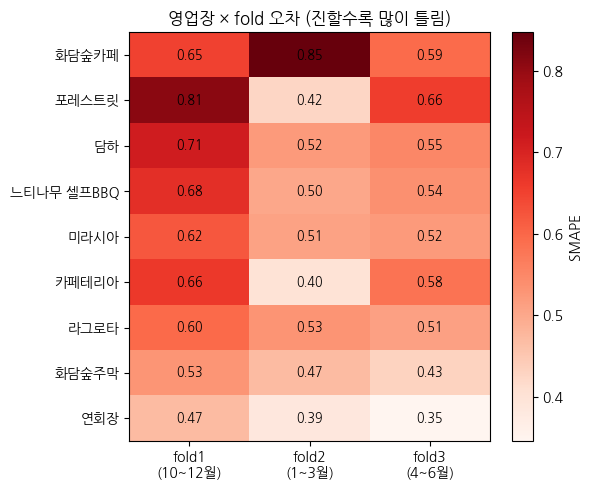

In [9]:
vf = scored.pivot_table(index='venue', columns='fold', values='smape', aggfunc='mean')
vf['평균'] = vf.mean(1)
vf = vf.sort_values('평균', ascending=False)
plt.figure(figsize=(6, 5))
plt.imshow(vf.drop(columns='평균').values, cmap='Reds', aspect='auto')
plt.colorbar(label='SMAPE')
plt.xticks(range(3), ['fold1\n(10~12월)', 'fold2\n(1~3월)', 'fold3\n(4~6월)'])
plt.yticks(range(len(vf)), vf.index)
for i in range(len(vf)):
    for j in range(3):
        plt.text(j, i, f'{vf.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
plt.title('영업장 × fold 오차 (진할수록 많이 틀림)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'w2_01_venue_fold.png', dpi=120); plt.show()

### 3-2. 시간에 따라 오차가 어떻게 변하나? (주 단위)
검증 주(7일)마다 영업장별 점수를 그립니다. **갑자기 튀어 오르는 주 = 시즌 전환 시점**일 가능성이 높아요.

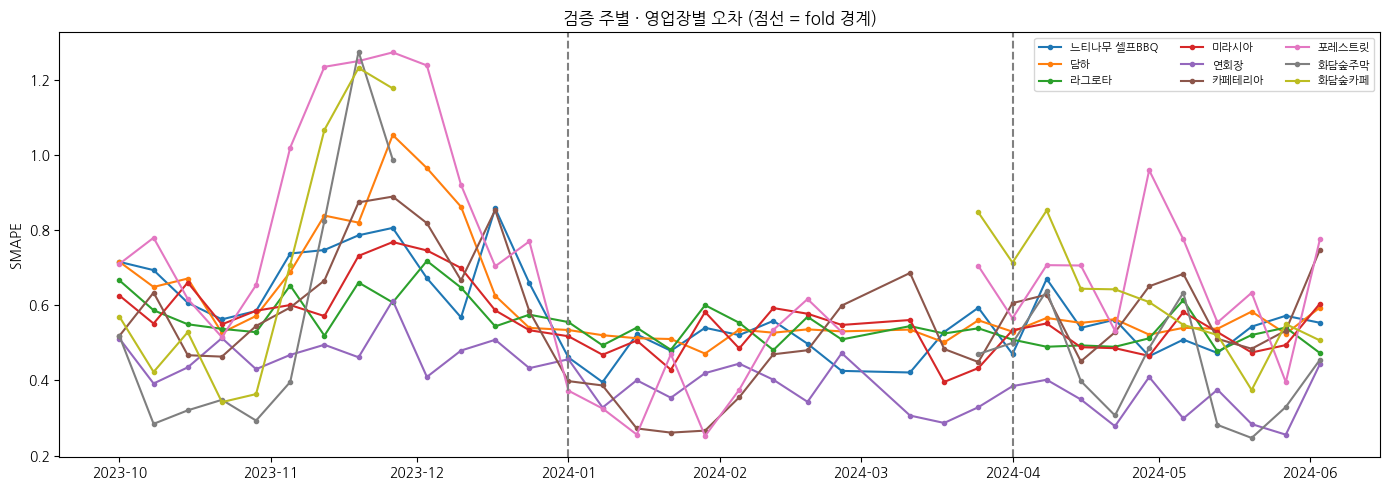

오차가 가장 컸던 (주, 영업장) TOP 10


,,SMAPE
window_start,venue,
2023-11-19,화담숲주막,1.275
2023-11-26,포레스트릿,1.273
2023-11-19,포레스트릿,1.250
2023-12-03,포레스트릿,1.239
2023-11-12,포레스트릿,1.235
2023-11-19,화담숲카페,1.232
2023-11-26,화담숲카페,1.177
2023-11-12,화담숲카페,1.067
2023-11-26,담하,1.053


In [10]:
weekly = scored.groupby(['window_start', 'venue'])['smape'].mean().unstack()
fig, ax = plt.subplots(figsize=(14, 5))
for v in weekly.columns:
    ax.plot(weekly.index, weekly[v], marker='o', markersize=3, label=v)
for a, _ in FOLDS[1:]:
    ax.axvline(pd.Timestamp(a), color='gray', linestyle='--')
ax.set_ylabel('SMAPE'); ax.set_title('검증 주별 · 영업장별 오차 (점선 = fold 경계)')
ax.legend(ncol=3, fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / 'w2_02_weekly_venue.png', dpi=120); plt.show()

print('오차가 가장 컸던 (주, 영업장) TOP 10')
display(weekly.stack().sort_values(ascending=False).head(10).round(3).to_frame('SMAPE'))

### 3-3. 며칠 뒤 예측일수록 더 틀리나? / 요일별 오차
- 상식적으로 +1일보다 +7일이 더 어려울 것 같은데, 실제로도 그런지 확인합니다.
- 요일별로 차이가 크다면 요일 패턴을 덜 배운 것일 수 있어요.

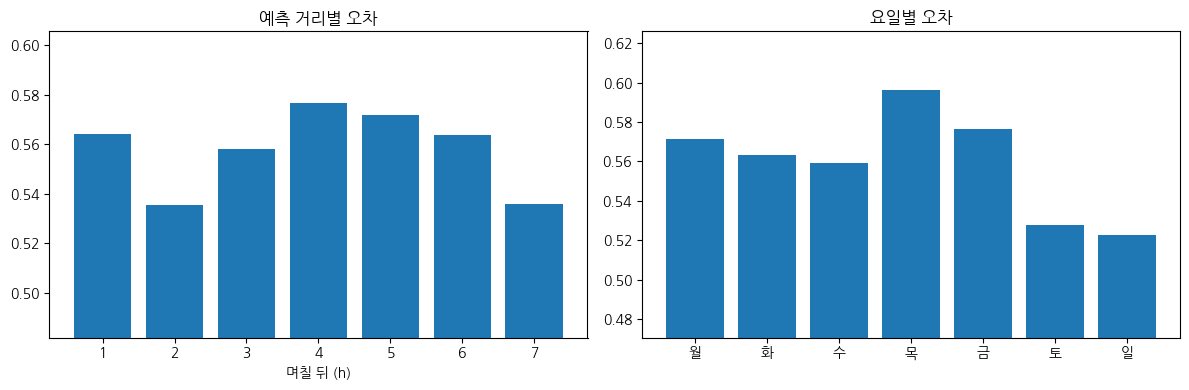

h,1,2,3,4,5,6,7
h별,0.564,0.535,0.558,0.577,0.572,0.564,0.536


dow,월,화,수,목,금,토,일
요일별,0.571,0.564,0.559,0.596,0.577,0.528,0.523


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
by_h = scored.groupby('h')['smape'].mean()
ax[0].bar(by_h.index, by_h.values); ax[0].set_xlabel('며칠 뒤 (h)'); ax[0].set_title('예측 거리별 오차')
ax[0].set_ylim(by_h.min() * 0.9, by_h.max() * 1.05)
dow_name = ['월', '화', '수', '목', '금', '토', '일']
by_dow = scored.groupby('dow')['smape'].mean()
ax[1].bar([dow_name[i] for i in by_dow.index], by_dow.values); ax[1].set_title('요일별 오차')
ax[1].set_ylim(by_dow.min() * 0.9, by_dow.max() * 1.05)
plt.tight_layout(); plt.savefig(FIG_DIR / 'w2_03_h_dow.png', dpi=120); plt.show()
display(pd.DataFrame({'h별': by_h.round(3)}).T); display(pd.DataFrame({'요일별': by_dow.rename(dict(enumerate(dow_name))).round(3)}).T)

## 4. 상황별 오차: "업장 휴장"과 "메뉴만 안 팔림" 구분하기 ⭐

1주차 질문에서 나온 아이디어예요.
> "막걸리 하나만 0인 것"과 "막걸리가 속한 **업장 전체가** 0인 것"은 의미가 다르다.

그래서 각 (검증 주, 메뉴)를 **입력 28일만 보고** 아래 5가지 상황으로 나눕니다. (위에서부터 먼저 해당되는 것)

| 상황 | 판단 기준 (입력 28일 기준) | 해석 |
|------|--------------------------|------|
| ① 업장 휴장 추정 | 영업장 전체가 **최근 7일 동안 0** | 가게 문 닫음 |
| ② 업장 재개장 직후 | 영업장이 앞 21일은 0, **최근 7일에 다시 판매** | 막 문을 염 |
| ③ 메뉴만 28일 0 | 영업장은 영업 중인데 **이 메뉴만 28일 내내 0** | 단종·비인기 메뉴 |
| ④ 메뉴 최근 7일 0 | 28일 중 판매는 있었지만 최근 7일은 0 | 판매가 뜸해짐 |
| ⑤ 정상 판매 | 그 외 | 평소대로 팔리는 중 |

아래 표에서 볼 것:
- **채점 건수:** 그 상황에서 실제로 팔려서 채점된 날 수
- **평균 SMAPE:** 그 상황에서 얼마나 틀리나
- **오차 비중:** 전체 오차 중 몇 %가 그 상황에서 나왔나 → **고치면 효과가 큰 곳**

,전체 건수(0 포함),채점건수,팔린 비율(%),평균SMAPE,오차 비중(%)
상황,,,,,
① 업장 휴장 추정,2884,368,12.760,0.543,1.419
② 업장 재개장 직후,175,135,77.143,0.575,0.551
③ 메뉴만 28일 0,2975,67,2.252,0.768,0.365
④ 메뉴 최근 7일 0,2268,459,20.238,0.554,1.805
⑤ 정상 판매,40334,24194,59.984,0.558,95.860


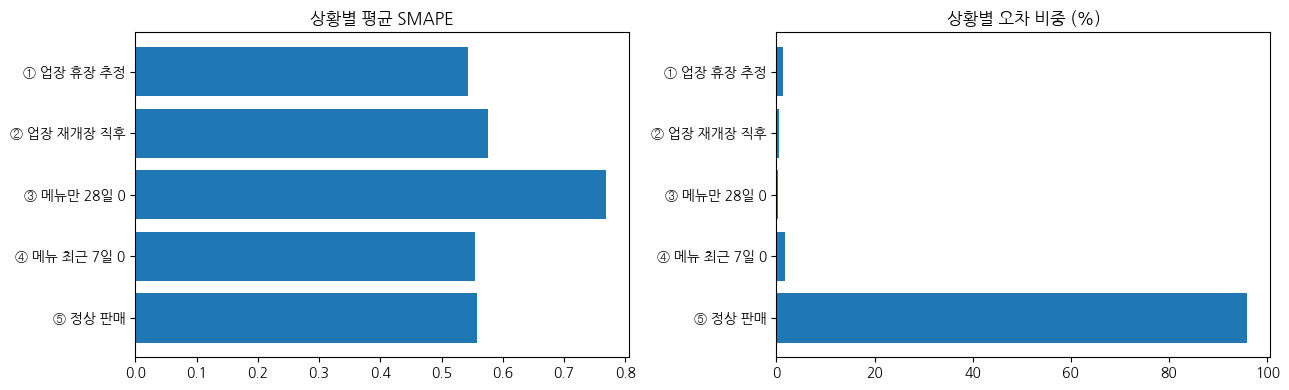

fold별 상황 분포 (채점건수)


fold,1,2,3
상황,,,
① 업장 휴장 추정,0,368,0
② 업장 재개장 직후,0,0,135
③ 메뉴만 28일 0,43,12,12
④ 메뉴 최근 7일 0,178,159,122
⑤ 정상 판매,9449,7916,6829


In [12]:
def situation(df):
    s = np.full(len(df), '⑤ 정상 판매', dtype=object)
    s[(df['menu_last7'] == 0).values] = '④ 메뉴 최근 7일 0'
    s[(df['menu_28'] == 0).values] = '③ 메뉴만 28일 0'
    s[((df['venue_first21'] == 0) & (df['venue_last7'] > 0)).values] = '② 업장 재개장 직후'
    s[(df['venue_last7'] == 0).values] = '① 업장 휴장 추정'
    return s

err['상황'] = situation(err)
scored['상황'] = situation(scored)

sit = scored.groupby('상황').agg(채점건수=('smape', 'size'), 평균SMAPE=('smape', 'mean'), 오차합=('smape', 'sum'))
sit['오차 비중(%)'] = sit['오차합'] / sit['오차합'].sum() * 100
all_cnt = err.groupby('상황').size().rename('전체 건수(0 포함)')
sit = sit.join(all_cnt, how='right').fillna(0)
sit['팔린 비율(%)'] = sit['채점건수'] / sit['전체 건수(0 포함)'] * 100
sit = sit[['전체 건수(0 포함)', '채점건수', '팔린 비율(%)', '평균SMAPE', '오차 비중(%)']].round(3)
display(sit)
sit.to_csv(RESULT_DIR / 'week2_error_by_situation.csv', encoding='utf-8-sig')

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(sit.index[::-1], sit['평균SMAPE'][::-1]); ax[0].set_title('상황별 평균 SMAPE')
ax[1].barh(sit.index[::-1], sit['오차 비중(%)'][::-1]); ax[1].set_title('상황별 오차 비중 (%)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'w2_04_situation.png', dpi=120); plt.show()

print('fold별 상황 분포 (채점건수)')
display(scored.pivot_table(index='상황', columns='fold', values='smape', aggfunc='size').fillna(0).astype(int))

> 📝 **읽는 법**
> - "팔린 비율"이 ③보다 ①에서 높다면 → **휴장 메뉴는 다시 팔릴 가능성이 높고, 단종 메뉴는 낮다**는 1주차 생각이 데이터로 확인된 것!
> - "오차 비중"이 큰 상황 = 3주차에 피처를 추가해서 공략할 1순위

## 5. 보험 전략 점검: 0이던 메뉴에 모델은 몇 개를 예측했나?

1주차에 이야기한 아이디어:
> 안 팔린 날은 채점하지 않으니, **0이던 메뉴도 "팔린다면 몇 개"를 적어두는 게 손해 없는 보험**이다.

모델이 실제로 그렇게 하고 있는지 확인합니다.
- **예측 중앙값이 1보다 한참 작다** → 보험이 약함 → 3주차에 보정 필요
- **팔렸을 때의 실제값과 비슷한 크기** → 이미 잘 하고 있음

,예측 중앙값(전체),예측 < 1 비율(%),팔렸을 때 실제 중앙값,팔렸을 때 예측 중앙값,팔렸을 때 SMAPE
상황,,,,,
① 업장 휴장 추정,22.39,2.67,3.0,3.06,0.54
② 업장 재개장 직후,16.46,0.00,37.0,18.81,0.58
③ 메뉴만 28일 0,6.64,0.47,4.0,7.77,0.77
④ 메뉴 최근 7일 0,2.16,10.27,1.0,2.04,0.55
⑤ 정상 판매,3.62,0.88,5.0,5.46,0.56


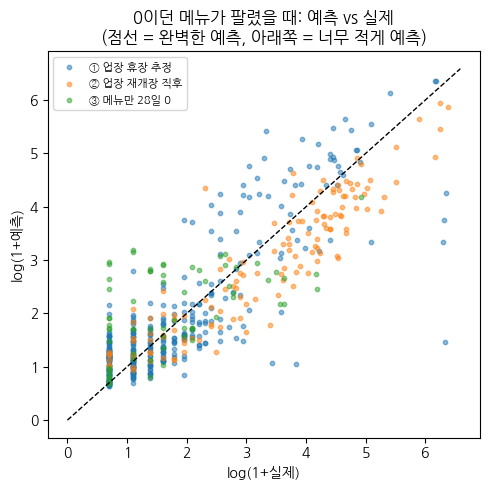

In [13]:
check = []
for s in ['① 업장 휴장 추정', '② 업장 재개장 직후', '③ 메뉴만 28일 0', '④ 메뉴 최근 7일 0', '⑤ 정상 판매']:
    a = err[err['상황'] == s]; b = scored[scored['상황'] == s]
    if len(a) == 0:
        continue
    check.append({'상황': s,
                  '예측 중앙값(전체)': a['pred'].median(),
                  '예측 < 1 비율(%)': (a['pred'] < 1).mean() * 100,
                  '팔렸을 때 실제 중앙값': b['true'].median() if len(b) else np.nan,
                  '팔렸을 때 예측 중앙값': b['pred'].median() if len(b) else np.nan,
                  '팔렸을 때 SMAPE': b['smape'].mean() if len(b) else np.nan})
check = pd.DataFrame(check).set_index('상황').round(2)
display(check)

# 휴장/재개장 상황에서 실제로 팔린 날: 예측 vs 실제 산점도
sub = scored[scored['상황'].isin(['① 업장 휴장 추정', '② 업장 재개장 직후', '③ 메뉴만 28일 0'])]
if len(sub):
    plt.figure(figsize=(5, 5))
    for s, g in sub.groupby('상황'):
        plt.scatter(np.log1p(g['true']), np.log1p(g['pred']), s=10, alpha=0.5, label=s)
    lim = np.log1p(max(sub['true'].max(), sub['pred'].max())) + 0.2
    plt.plot([0, lim], [0, lim], 'k--', lw=1); plt.xlabel('log(1+실제)'); plt.ylabel('log(1+예측)')
    plt.title('0이던 메뉴가 팔렸을 때: 예측 vs 실제\n(점선 = 완벽한 예측, 아래쪽 = 너무 적게 예측)')
    plt.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG_DIR / 'w2_05_insurance.png', dpi=120); plt.show()

## 6. 어떤 메뉴가 어렵고, 연회장은 왜 잘 맞나?

SMAPE는 **비율** 오차라서 판매량이 작은 메뉴에 불리합니다.
- 실제 2개, 예측 1개 → SMAPE 0.67
- 실제 200개, 예측 199개 → SMAPE 0.005

같은 "1개 차이"인데 점수는 100배 넘게 차이 나요. 그래서 **메뉴의 판매 규모·판매 빈도**와 오차의 관계를 봅니다.

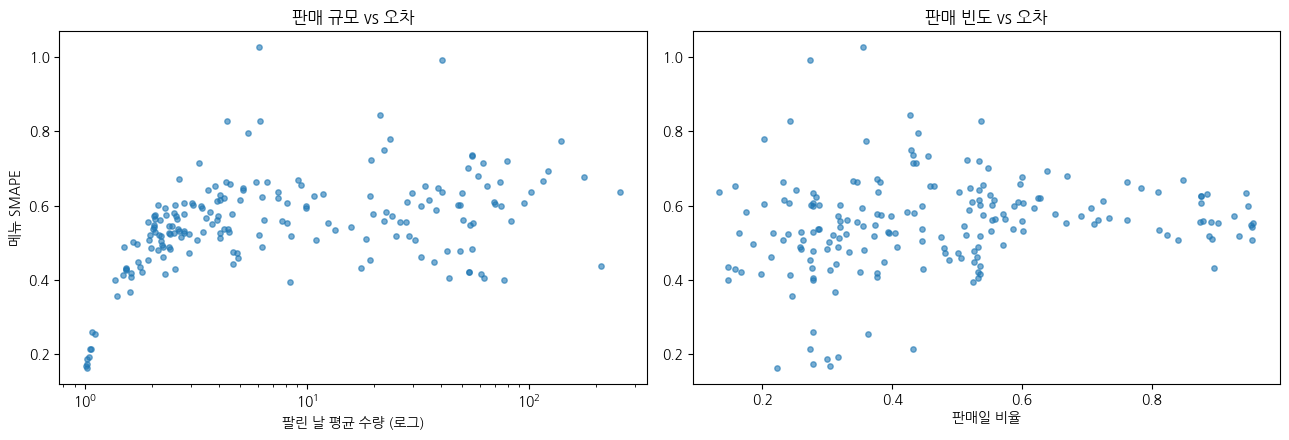

상관계수: {'SMAPE': 1.0, '팔린날 평균수량': 0.482, '판매일 비율': 0.242, '변동계수': 0.544}

가장 어려운 메뉴 TOP 15


,SMAPE,채점일수,팔린날 평균수량,판매일 비율,변동계수,영업장
menu,,,,,,
담하_갑오징어 비빔밥,1.026,23,6.095,0.355,1.034,담하
카페테리아_오픈푸드,0.993,70,40.324,0.273,2.653,카페테리아
느티나무 셀프BBQ_스프라이트 (단체),0.843,100,21.233,0.427,0.895,느티나무 셀프BBQ
라그로타_빵 추가 (1인),0.828,105,6.126,0.538,0.837,라그로타
담하_라면사리,0.828,63,4.341,0.242,1.456,담하
연회장_Cookie Platter,0.795,111,5.410,0.440,0.886,연회장
담하_(단체) 한우 우거지 국밥,0.781,54,23.648,0.203,0.796,담하
카페테리아_단체식 18000(신),0.774,107,139.534,0.359,0.826,카페테리아
느티나무 셀프BBQ_콜라 (단체),0.750,101,22.092,0.429,0.875,느티나무 셀프BBQ


In [14]:
menu_err = scored.groupby('menu').agg(SMAPE=('smape', 'mean'), 채점일수=('smape', 'size'))
sold = wide.where(wide > 0)
menu_err['팔린날 평균수량'] = sold.mean().reindex(menu_err.index)
menu_err['판매일 비율'] = (wide > 0).mean().reindex(menu_err.index)
menu_err['변동계수'] = (sold.std() / sold.mean()).reindex(menu_err.index)   # 팔린 날끼리 수량이 얼마나 들쭉날쭉한가
menu_err['영업장'] = [VENUE_OF[m] for m in menu_err.index]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(menu_err['팔린날 평균수량'], menu_err['SMAPE'], s=15, alpha=0.6)
ax[0].set_xscale('log'); ax[0].set_xlabel('팔린 날 평균 수량 (로그)'); ax[0].set_ylabel('메뉴 SMAPE')
ax[0].set_title('판매 규모 vs 오차')
ax[1].scatter(menu_err['판매일 비율'], menu_err['SMAPE'], s=15, alpha=0.6)
ax[1].set_xlabel('판매일 비율'); ax[1].set_title('판매 빈도 vs 오차')
plt.tight_layout(); plt.savefig(FIG_DIR / 'w2_06_menu_scale.png', dpi=120); plt.show()
print('상관계수:', menu_err[['SMAPE', '팔린날 평균수량', '판매일 비율', '변동계수']].corr(method='spearman')['SMAPE'].round(3).to_dict())

print('\n가장 어려운 메뉴 TOP 15')
display(menu_err.sort_values('SMAPE', ascending=False).head(15).round(3))

In [15]:
venue_prof = menu_err.groupby('영업장').agg(
    SMAPE=('SMAPE', 'mean'), 메뉴수=('SMAPE', 'size'),
    팔린날_평균수량_중앙값=('팔린날 평균수량', 'median'),
    판매일비율_평균=('판매일 비율', 'mean'), 변동계수_중앙값=('변동계수', 'median'),
).sort_values('SMAPE')
display(venue_prof.round(3))
print('연회장 메뉴 목록:', [m.split('_', 1)[1] for m in MENUS if VENUE_OF[m] == '연회장'])
menu_err.to_csv(RESULT_DIR / 'week2_menu_errors.csv', encoding='utf-8-sig')

,SMAPE,메뉴수,팔린날_평균수량_중앙값,판매일비율_평균,변동계수_중앙값
영업장,,,,,
연회장,0.384,23,2.305,0.339,0.522
화담숲주막,0.477,8,46.305,0.529,0.921
라그로타,0.547,25,2.663,0.402,0.692
미라시아,0.548,31,2.624,0.480,0.725
카페테리아,0.551,24,29.805,0.559,0.929
느티나무 셀프BBQ,0.572,23,3.986,0.398,0.807
담하,0.612,42,4.432,0.531,0.805
포레스트릿,0.625,12,55.905,0.579,1.207
화담숲카페,0.628,5,38.931,0.526,0.839


연회장 메뉴 목록: ['Cass Beer', 'Conference L1', 'Conference L2', 'Conference L3', 'Conference M1', 'Conference M8', 'Conference M9', 'Convention Hall', 'Cookie Platter', 'Grand Ballroom', 'OPUS 2', 'Regular Coffee', '골뱅이무침', '공깃밥', '돈목살 김치찌개 (밥포함)', '로제 치즈떡볶이', '마라샹궈', '매콤 무뼈닭발&계란찜', '모둠 돈육구이(3인)', '삼겹살추가 (200g)', '야채추가', '왕갈비치킨', '주먹밥 (2ea)']


> 📝 **읽는 법:** 연회장이 다른 영업장보다 `판매일비율`이 높거나, `변동계수`가 낮거나(수량이 일정함), 메뉴 수가 적다면 그게 잘 맞는 이유예요.
> 반대로 **판매량이 작고 드물게 팔리는 메뉴**가 오차의 주범이라면, 3주차에는 이런 메뉴를 위한 피처(같은 영업장 메뉴들의 흐름 빌려오기)가 효과적일 거예요.

## 7. 진단 실험 ①: 공부량을 줄이면 얼마나 나빠지나?

**질문:** fold1이 나빴던 게 "공부량(학습 기간) 부족" 때문인가?

**방법:** fold3(2024년 4~6월 검증)에서 **검증 직전 N개월치로만** 학습시켜 봅니다.
- 3개월: 2024년 1~3월만 (겨울만 보고 봄을 맞힘)
- 6개월, 9개월: 점점 늘림
- 12개월: **작년 봄(2023년 4~6월)이 포함되기 시작**
- 전체: 약 15개월

**읽는 법:**
- 기간이 줄수록 점수가 확 나빠짐 → **공부량이 중요 = fold1이 나쁜 데에 공부량 부족도 큰 원인**
- 12개월에서 갑자기 좋아짐 → **"작년 같은 계절"을 본 것이 중요**
- 별 차이 없음 → 공부량보다 **계절 자체의 어려움**이 주원인

(시간 절약을 위해 시드 1개로 돌립니다. 2장에서 잰 흔들림 크기를 감안해서 읽어 주세요.)

3개월   학습 → fold3 SMAPE 0.5704
6개월   학습 → fold3 SMAPE 0.5829
9개월   학습 → fold3 SMAPE 0.5708
12개월  학습 → fold3 SMAPE 0.5207
전체    학습 → fold3 SMAPE 0.5214


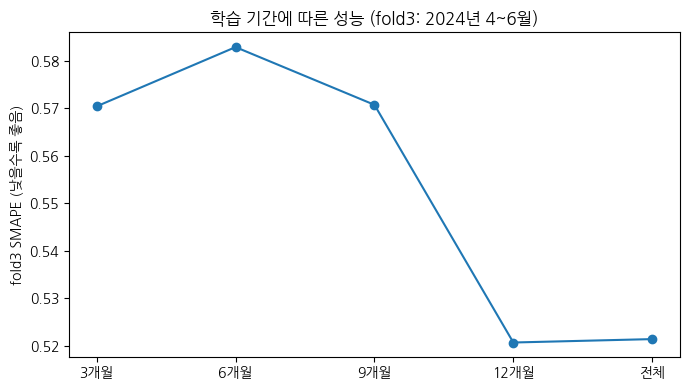

In [16]:
amount = {}
for months in [3, 6, 9, 12, None]:
    label = '전체' if months is None else f'{months}개월'
    days = None if months is None else months * 30
    sc = run_cv(train_days=days, seeds=[42], folds=(2,), verbose=False)
    amount[label] = sc.iloc[0, 0]
    print(f'{label:5s} 학습 → fold3 SMAPE {amount[label]:.4f}')
amount = pd.Series(amount)
plt.figure(figsize=(7, 4))
plt.plot(amount.index, amount.values, marker='o')
plt.ylabel('fold3 SMAPE (낮을수록 좋음)'); plt.title('학습 기간에 따른 성능 (fold3: 2024년 4~6월)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'w2_07_train_amount.png', dpi=120); plt.show()
amount.to_csv(RESULT_DIR / 'week2_train_amount.csv', encoding='utf-8-sig')

## 8. 진단 실험 ②: `dayofyear`(1년 중 며칠째 즉, 예측할 날이 1년 중 어디쯤인지를 알려주는 피처)를 빼면?

1주차 피처 중요도 2위였지만, 데이터가 1.5년뿐이라 **"2023년 ○월 ○일엔 많이 팔렸다"를 외우는** 위험이 있었어요.
빼고 돌려서 **판정 규칙(2장)** 으로 비교합니다. `month`(월)는 남겨둬서 대략적인 계절 정보는 유지해요.

**읽는 법:**
- ✅ 개선 또는 ➖ 차이 없음 → 외우기용 변수였다 → **빼는 게 더 안전** (단순할수록 새 해에도 잘 통함)
- ❌ 악화 → 시즌 정보로 실제로 유용 → 남기되, 3주차 시즌 피처로 대체 가능한지 다시 시험

In [17]:
print('dayofyear 제거 × 시드 3개')
no_doy = run_cv(drop_cols=['dayofyear'])
EXPERIMENTS.append(judge('dayofyear 제거', no_doy, base_scores, NOISE))

dayofyear 제거 × 시드 3개
  seed 42: fold1=0.5914, fold2=0.5090, fold3=0.5222
  seed 2024: fold1=0.5945, fold2=0.5075, fold3=0.5227
  seed 7: fold1=0.5938, fold2=0.5075, fold3=0.5209
[dayofyear 제거] 평균 차이 -0.0149 (기준 ±0.0059) → ✅ 개선


,기존,새 실험,차이,확실한 변화 기준(±)
fold1,0.6421,0.5933,-0.0488,0.0110
fold2,0.5050,0.5080,0.0030,0.0053
fold3,0.5207,0.5219,0.0012,0.0013


## 9. 실험 기록표
앞으로 3주차부터 실험이 늘어날 때마다 **이 표에 한 줄씩 추가**됩니다. 그대로 `update.md`에 옮기면 돼요.

In [18]:
exp_df = pd.DataFrame(EXPERIMENTS).set_index('실험')
display(exp_df.round(4))
exp_df.to_csv(RESULT_DIR / 'experiment_log.csv', encoding='utf-8-sig')

,평균,평균차이,fold1,fold2,fold3,판정
실험,,,,,,
베이스라인 (E),0.5560,0.0000,0.6421,0.505,0.5207,기준
dayofyear 제거,0.5411,-0.0149,0.5933,0.508,0.5219,✅ 개선


## 10. 2주차 정리 ✍️
결과를 보고 아래 표를 채워 주세요 (또는 노트북을 다운로드해서 Claude에게 보내 같이 해석해도 좋아요).

| # | 질문 | 발견 (숫자와 함께) | 3주차에 할 일 |
|---|------|-------------------|--------------|
| 0 | 시드 흔들림 크기 | | 판정 기준으로 사용 |
| 1 | 가장 틀리는 영업장·주 | | |
| 1 | h(며칠 뒤)·요일별 차이 | | |
| 2 | 상황별 오차 (휴장/재개장/메뉴만 0) | | 휴장·재개장 피처 |
| 3 | 0이던 메뉴의 예측값 (보험) | | 필요 시 보정 |
| 4 | 판매 규모·빈도와 오차, 연회장이 잘 맞는 이유 | | 영업장 단위 피처 |
| 5 | 학습 기간 실험 결과 | | |
| 6 | dayofyear 제거 판정 | | 유지/제거 결정 |